# CODE 6.1: Prepare the Demo

> **Goal:** prepare the files the demo app needs, and make new photos to try it with.
>
> - **Input:**
>   - the original photos and masks (`data/raw/chewinggum/`), the crops and real defect boxes of notebooks 3.1 and 3.2
>   - the split file of split 1 (notebook 1.3) and the same-gum pairs of notebook 1.2 (`splits/same_gum_photos.csv`)
>   - the decisions of notebook 5.1 (`results/evaluation/test_decisions.csv`)
> - **Output:**
>   - `app/data/gallery/` and `app/data/gallery.csv`: the 9 test photos of split 1 that the app shows, with their real defect boxes, and the whole camera photo of one of them
>   - `test_photos/`: 9 new camera photos to try the app, and `test_photos/answers.csv` with the right answer of each
>   - `app/data/fingerprints.npz`: a small grey copy of every crop, so the app can tell when someone uploads a photo of the dataset
>
> The app uses the two models of split 1 that step 5 judged: PatchCore and YOLO with k = 40. This notebook trains nothing and scores nothing. The crops and boxes of steps 3 and 4 are not saved on GitHub (`data/` is in `.gitignore`), so the app gets its own small copies here.

### Why New Photos

> On a production line, the camera sends photos that no model has seen before. The test photos of step 5 were such photos once, but their results are already known. To try the app like a real machine, we make new photos:
>
> - **Good gum (4 photos):** in notebook 1.2, 6 gums turned out to be photographed twice, and the second photo was left out of the whole project. For 4 of them, the first photo is not a train photo of split 1, so no split 1 model learned from this gum. We mirror these photos from left to right, so they are new pictures. The light comes from below, so a mirrored gum still looks real (the same reason YOLO mirrors photos while it learns, notebook 4.2).
> - **Gum with a defect (5 photos):** we take a good test photo of split 1, mirror it, and copy a real defect onto it from a defect test photo of split 1. Neither model of split 1 learned from these test photos. The copy has soft edges and gets the same brightness as the gum around it.
> - **Full camera photos:** the new photos keep the size of the camera (1342 x 1118 pixels), so the app has to find and cut out the gum itself, with the rule of notebook 3.1.
>
> These photos are only for trying the app. They are not part of any result of this project.

### Words Used in This Notebook

> - **Mirror:** flip a photo from left to right, like looking in a mirror.
> - **Soft edges:** the copied defect fades into the gum over a few pixels, so there is no hard border.
> - **Fingerprint:** a very small grey copy of a crop (58 x 38 pixels). Two fingerprints are compared by the average difference of their pixels (0 to 255): almost 0 for the same photo, much more for two different photos.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths. `io`: keeps a JPEG in memory to test the fingerprints. `json`: writes the defect boxes as text in a table.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures.
> - `PIL` (Pillow): opens, mirrors, cuts and saves photos.
> - `scipy.ndimage`: finds the gum (as in notebook 3.1), grows the defect area and makes the soft edges.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os
import io
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `RAW_DIR`: the original photos and masks.
> - `CROP_DIR`, `CROP_TABLE_FILE`, `BOX_FILE`: the crops and their table (notebook 3.1), and the real defect boxes (notebook 3.2).
> - `SPLITS_DIR`: the split files (notebook 1.3) and the same-gum pairs (notebook 1.2).
> - `DECISIONS_FILE`: the decisions of both models on the test photos (notebook 5.1).
> - `APP_DATA_DIR`, `GALLERY_DIR`: where the app finds its photos and fingerprints.
> - `TEST_PHOTO_DIR`: the new photos, in the main folder so they are easy to find on GitHub.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

RAW_DIR = os.path.join(ROOT_DIR, "data", "raw", "chewinggum", "Data")
CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
CROP_TABLE_FILE = os.path.join(CROP_DIR, "crop_boxes.csv")
BOX_FILE = os.path.join(CROP_DIR, "yolo_boxes.csv")
SPLITS_DIR = os.path.join(ROOT_DIR, "splits")
DECISIONS_FILE = os.path.join(ROOT_DIR, "results", "evaluation", "test_decisions.csv")
APP_DATA_DIR = os.path.join(ROOT_DIR, "app", "data")
GALLERY_DIR = os.path.join(APP_DATA_DIR, "gallery")
TEST_PHOTO_DIR = os.path.join(ROOT_DIR, "test_photos")

for path, step in [(RAW_DIR, "Copy the 'chewinggum' folder into data/raw/ (see README)"), (CROP_TABLE_FILE, "Run notebook 3.1 first"),
                   (BOX_FILE, "Run notebook 3.2 first"), (DECISIONS_FILE, "Run notebook 5.1 first")]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"{os.path.relpath(path, ROOT_DIR)} not found. {step}.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLIT`, `K`: the app shows the models of split 1, with YOLO trained on k = 40 labeled defect photos.
> - `GALLERY`: the 9 test photos of split 1 in the app: 2 good gums and 3 defects that both models judge right, and 4 hard cases, one for every kind of mistake in split 1 (each model misses one defect and rejects one good gum).
> - `NEW_GOOD`: the 4 left-out photos (notebook 1.2) whose first photo is not a train photo of split 1. The code below checks this.
> - `NEW_DEFECTS`: 5 pairs (good test photo, defect test photo): one defect of each kind, and Anomaly/032, the photo PatchCore misses in all 3 splits (notebook 5.2), as a hard case. For the two missing-corner defects (Anomaly/036 and 032), we tried the good test photos and took the one whose gum outline fits the old gum best (Normal/332 and 471), so the broken corner sits cleanly on the new gum.
> - `ORDER`: the order of the new photos, so good and defect photos are mixed and the file name gives no hint.
> - `WINDOW_SIZE`, `FIND_SCALE`, `GUM_BRIGHTNESS`: the crop rule of notebook 3.1.
> - `SEARCH`, `OUTLINE_MARGIN`: the first guess of where the defect goes is improved by up to 30 pixels in each direction, by comparing the outline of both gums in a frame of 50 pixels around the defect.
> - `GROW`, `COVER`, `RING`, `SOFT_EDGE`, `BRIGHT_GUM`: how a defect is copied: its area grows by 6 pixels, up to 30 pixels around it the mat of the old photo also covers the gum of the new one, the brightness is matched in a 12-pixel ring around it (only on gum pixels brighter than 120), and the edge fades over about 2.5 pixels.
> - `MIN_PIECE`: defect pieces smaller than 10 pixels get no box (like the specks of notebook 3.1).
> - `MASK_CODE`: the number of each defect type in the masks (notebook 3.1).
> - `FINGERPRINT_SIZE`, `JPEG_QUALITY`, `GALLERY_QUALITY`: the fingerprint size, and the JPEG quality of the new photos and of the gallery photos.

In [3]:
SPLIT = 1
K = 40
GALLERY = ["Normal/422", "Normal/329", "Anomaly/006", "Anomaly/092", "Anomaly/070",
           "Anomaly/032", "Anomaly/026", "Normal/316", "Normal/118"]
NEW_GOOD = ["Normal/113", "Normal/216", "Normal/265", "Normal/351"]
NEW_DEFECTS = [("Normal/031", "Anomaly/040"), ("Normal/375", "Anomaly/087"), ("Normal/332", "Anomaly/036"),
               ("Normal/366", "Anomaly/069"), ("Normal/471", "Anomaly/032")]
ORDER = ["good 1", "defect 1", "good 2", "defect 2", "defect 3", "good 3", "defect 4", "defect 5", "good 4"]
WINDOW_SIZE = (928, 608)
FIND_SCALE = 4
GUM_BRIGHTNESS = 120
SEARCH = 30
OUTLINE_MARGIN = 50
GROW = 6
COVER = 30
RING = 12
SOFT_EDGE = 2.5
BRIGHT_GUM = 120
MIN_PIECE = 10
MASK_CODE = {1: "chunk of gum missing", 2: "corner missing", 3: "scratches", 4: "similar colour spot", 5: "small cracks"}
FINGERPRINT_SIZE = (58, 38)
JPEG_QUALITY = 95
GALLERY_QUALITY = 90

## Functions

### Short Name and Raw Photo

> `short_name()` turns `chewinggum/Data/Images/Normal/113.JPG` into `Normal/113`. `raw_photo()` opens an original photo by its short name, and `raw_mask()` its mask (the number of the defect type in every pixel, 0 = no defect).

In [4]:
def short_name(rel_path):
    return rel_path.split("Images/")[-1].rsplit(".", 1)[0]


def raw_photo(name):
    return Image.open(os.path.join(RAW_DIR, "Images", f"{name}.JPG")).convert("RGB")


def raw_mask(name):
    return np.asarray(Image.open(os.path.join(RAW_DIR, "Masks", f"{name}.png")))

### Find the Gum and Place the Window

> The same two functions as in notebook 3.1, so the app cuts a new photo exactly like the photos of the dataset:
>
> - `find_gum_box()`: makes the photo 4 times smaller, takes the bright pixels (the gum is much brighter than the black mat), keeps the biggest bright piece and returns its box.
> - `place_window()`: puts the 928 x 608 window in the middle of the gum box, and moves it inside the photo if needed.

In [5]:
def find_gum_box(gray, scale, brightness):
    small = gray.resize((gray.width // scale, gray.height // scale), Image.BILINEAR)
    bright = ndimage.uniform_filter(np.asarray(small, dtype=float), 3) > brightness
    pieces, n_pieces = ndimage.label(bright)
    sizes = np.bincount(pieces.ravel())
    sizes[0] = 0
    rows, cols = np.nonzero(pieces == sizes.argmax())
    return cols.min() * scale, rows.min() * scale, (cols.max() + 1) * scale, (rows.max() + 1) * scale


def place_window(gum_box, window_size, photo_size):
    left, top, right, bottom = gum_box
    width, height = window_size
    photo_width, photo_height = photo_size
    window_left = (left + right) // 2 - width // 2
    window_top = (top + bottom) // 2 - height // 2
    window_left = min(max(window_left, 0), photo_width - width)
    window_top = min(max(window_top, 0), photo_height - height)
    return window_left, window_top, window_left + width, window_top + height

### Where the Defect Goes

> `defect_shift()` decides how far the defect moves from its own gum to the new gum, in pixels to the right (`dx`) and down (`dy`). It looks at where the defect sits on its own gum box:
>
> - **Near a corner** (less than 22% of the width from the left or right side and less than 30% of the height from the top or bottom): the defect keeps the same distance to that corner of the new gum. A missing corner must stay exactly on the corner.
> - **Anywhere else:** the defect keeps the same place in percent of the gum box, for example 40% from the left and 50% from the top.

In [6]:
def defect_shift(source_gum, target_gum, codes):
    rows, cols = np.nonzero(codes)
    centre_x, centre_y = cols.mean(), rows.mean()
    source_left, source_top, source_right, source_bottom = source_gum
    target_left, target_top, target_right, target_bottom = target_gum
    share_x = (centre_x - source_left) / (source_right - source_left)
    share_y = (centre_y - source_top) / (source_bottom - source_top)
    if min(share_x, 1 - share_x) < 0.22 and min(share_y, 1 - share_y) < 0.3:
        dx = target_left - source_left if share_x < 0.5 else target_right - source_right
        dy = target_top - source_top if share_y < 0.5 else target_bottom - source_bottom
    else:
        dx = target_left + share_x * (target_right - target_left) - centre_x
        dy = target_top + share_y * (target_bottom - target_top) - centre_y
    return int(round(dx)), int(round(dy))

### Match the Outline

> The first guess of `defect_shift()` can be a few pixels off, because no two gums have exactly the same shape. For a missing corner this matters: the broken edge must sit exactly on the edge of the new gum. `match_outline()` improves the guess:
>
> 1. **Gum pixels:** in both photos, every pixel brighter than `brightness` (after a small blur) counts as gum.
> 2. **Frame:** only the area around the defect counts, `margin` pixels on every side, without the defect itself (the defect changes the outline of its own gum).
> 3. **Try every shift** up to `search` pixels away from the guess, and count how many pixels disagree (gum in one photo, mat in the other).
> 4. **Keep the best shift.** A very small extra cost for every pixel away from the guess decides between equally good shifts, so a defect in the middle of the gum, where everything is gum, stays at the guess.

In [7]:
def match_outline(source, target, codes, guess, search, margin, brightness):
    source_gum = ndimage.uniform_filter(np.asarray(source.convert("L"), dtype=float), 5) > brightness
    target_gum = ndimage.uniform_filter(np.asarray(target.convert("L"), dtype=float), 5) > brightness
    area = codes > 0
    rows, cols = np.nonzero(area)
    top, bottom = max(rows.min() - margin, 0), rows.max() + margin
    left, right = max(cols.min() - margin, 0), cols.max() + margin
    frame = source_gum[top:bottom, left:right]
    counted = ~ndimage.binary_dilation(area, iterations=6)[top:bottom, left:right]
    best_cost, best_shift = np.inf, guess
    for dy in range(guess[1] - search, guess[1] + search + 1):
        for dx in range(guess[0] - search, guess[0] + search + 1):
            moved = target_gum[top + dy:bottom + dy, left + dx:right + dx]
            if moved.shape != frame.shape:
                continue
            cost = (frame != moved)[counted].mean() + 1e-5 * (abs(dx - guess[0]) + abs(dy - guess[1]))
            if cost < best_cost:
                best_cost, best_shift = cost, (dx, dy)
    return best_shift

### Copy a Defect

> `copy_defect()` copies the defect of one photo onto another:
>
> 1. **Area:** the defect pixels of the mask, grown by `grow` pixels, so the copy also takes a thin edge of normal gum around the defect. Near the defect (`cover` pixels around it), the area also takes every pixel where the old photo shows mat but the new photo shows gum. So where a corner is missing in the old gum, it is also missing in the new gum.
> 2. **Brightness:** in a ring around the area, it compares the gum pixels of both photos and finds one factor per colour (`gain`) that makes the copied pixels as bright as the new gum. Only pixels brighter than `bright` count, so the black mat does not change the factor.
> 3. **Soft edges:** the area is blurred a little (`alpha`, from 0 to 1), and every copied pixel is a mix of the copy and the new photo: fully the copy inside the defect, fading to the new photo at the edge.
> 4. **New mask:** the mask moves with the defect, so we know where the real defect of the new photo is.

In [8]:
def copy_defect(target, source, codes, shift, grow, cover, ring, soft_edge, bright):
    dx, dy = shift
    area = ndimage.binary_dilation(codes > 0, iterations=grow)
    source_gum = ndimage.uniform_filter(source.mean(axis=2), 5) > bright
    target_gum = ndimage.uniform_filter(np.roll(target.mean(axis=2), (-dy, -dx), axis=(0, 1)), 5) > bright
    near = ndimage.binary_dilation(codes > 0, iterations=cover)
    area |= near & ~source_gum & target_gum
    around = ndimage.binary_dilation(area, iterations=ring) & ~area
    rows, cols = np.nonzero(around)
    source_ring = source[rows, cols].astype(float)
    target_ring = target[rows + dy, cols + dx].astype(float)
    gum = (source_ring.mean(axis=1) > bright) & (target_ring.mean(axis=1) > bright)
    gain = target_ring[gum].mean(axis=0) / source_ring[gum].mean(axis=0)
    alpha = ndimage.gaussian_filter(area.astype(float), soft_edge)
    rows, cols = np.nonzero(alpha > 0.01)
    mix = alpha[rows, cols][:, None]
    copied = np.clip(source[rows, cols].astype(float) * gain, 0, 255)
    result = target.astype(float)
    result[rows + dy, cols + dx] = mix * copied + (1 - mix) * result[rows + dy, cols + dx]
    moved = np.zeros_like(codes)
    rows, cols = np.nonzero(codes)
    moved[rows + dy, cols + dx] = codes[rows, cols]
    return np.clip(result, 0, 255).astype(np.uint8), moved

### Defect Boxes

> `defect_boxes()` turns a mask into boxes, one per separate piece of each defect type (pieces that touch, also at a corner, are one piece). Pieces smaller than `min_pixels` get no box. Each box is `[left, top, right, bottom, type]` in pixels of the photo.

In [9]:
def defect_boxes(codes, min_pixels, mask_code):
    boxes = []
    for code in np.unique(codes[codes > 0]):
        pieces, n_pieces = ndimage.label(codes == code, structure=np.ones((3, 3), dtype=bool))
        for piece in range(1, n_pieces + 1):
            rows, cols = np.nonzero(pieces == piece)
            if len(rows) >= min_pixels:
                boxes.append([int(cols.min()), int(rows.min()), int(cols.max()) + 1, int(rows.max()) + 1, mask_code[int(code)]])
    return boxes

### Cut Out the Gum

> `cut_gum()` applies the crop rule of notebook 3.1 to a whole photo and returns the crop and its window. The app does exactly this with every photo that is not already a crop.

In [10]:
def cut_gum(photo, window_size, scale, brightness):
    gum_box = find_gum_box(photo.convert("L"), scale=scale, brightness=brightness)
    window = place_window(gum_box, window_size, photo.size)
    return photo.crop(window), window

### Fingerprint

> `fingerprint()` makes the crop grey and very small (58 x 38 pixels, each pixel the average of a 16 x 16 block). `fingerprint_distance()` is the average difference between two fingerprints, from 0 (the same) to 255.

In [11]:
def fingerprint(crop, size):
    return np.asarray(crop.convert("L").resize(size, Image.BOX), dtype=np.float32)


def fingerprint_distance(first, second):
    return float(np.abs(first - second).mean())

### Draw Boxes

> `draw_boxes()` draws boxes on a picture: `[left, top, right, bottom, ...]`, moved by `offset` (for example the corner of the crop window). Only for the figures.

In [12]:
def draw_boxes(ax, boxes, offset=(0, 0), color="red"):
    for left, top, right, bottom, *rest in boxes:
        ax.add_patch(Rectangle((left - offset[0], top - offset[1]), right - left, bottom - top,
                               fill=False, edgecolor=color, linewidth=1.5))

## 1. Photos for the App Gallery

### The 9 Gallery Photos

> For every gallery photo: is it really a test photo of split 1, the right answer, and the decision of both models (notebook 5.1). A photo is a **hard case** when at least one model is wrong.

In [13]:
split = pd.read_csv(os.path.join(SPLITS_DIR, f"split_{SPLIT}.csv"))
split["name"] = split["image"].map(short_name)
part_of = dict(zip(split["name"], split["split"]))

decisions = pd.read_csv(DECISIONS_FILE).fillna({"defect_types": ""})
decisions = decisions[(decisions["split"] == SPLIT) & decisions["model"].isin(["PatchCore", f"YOLO k = {K}"])].copy()
decisions["name"] = decisions["image"].map(short_name)
decided = decisions.pivot_table(index=["name", "is_defect", "defect_types"], columns="model", values="rejected",
                                aggfunc="first").reset_index()
decided["right answer"] = np.where(decided["is_defect"], "REJECT", "PASS")
for model in ["PatchCore", f"YOLO k = {K}"]:
    decided[model] = np.where(decided[model], "REJECT", "PASS")
decided["hard case"] = (decided["PatchCore"] != decided["right answer"]) | (decided[f"YOLO k = {K}"] != decided["right answer"])

gallery = decided.set_index("name").loc[GALLERY].reset_index()
gallery.insert(1, "part", gallery["name"].map(part_of))
print("All gallery photos are test photos of split 1:", (gallery["part"] == "test").all())
print("Hard cases in all test photos of split 1:", decided.loc[decided["hard case"], "name"].tolist())
gallery[["name", "part", "defect_types", "right answer", "PatchCore", f"YOLO k = {K}", "hard case"]]

All gallery photos are test photos of split 1: True
Hard cases in all test photos of split 1: ['Anomaly/026', 'Anomaly/032', 'Anomaly/039', 'Normal/118', 'Normal/188', 'Normal/190', 'Normal/316', 'Normal/373', 'Normal/499']


model,name,part,defect_types,right answer,PatchCore,YOLO k = 40,hard case
0,Normal/422,test,,PASS,PASS,PASS,False
1,Normal/329,test,,PASS,PASS,PASS,False
2,Anomaly/006,test,"chunk of gum missing,small cracks",REJECT,REJECT,REJECT,False
3,Anomaly/092,test,similar colour spot,REJECT,REJECT,REJECT,False
4,Anomaly/070,test,scratches,REJECT,REJECT,REJECT,False
5,Anomaly/032,test,"corner missing,scratches",REJECT,PASS,REJECT,True
6,Anomaly/026,test,corner missing,REJECT,REJECT,PASS,True
7,Normal/316,test,,PASS,REJECT,PASS,True
8,Normal/118,test,,PASS,PASS,REJECT,True


> **What we see:**
>
> - All 9 gallery photos are test photos of split 1, so neither model learned from them.
> - Split 1 has 9 hard cases among its 150 test photos. The gallery shows 4 of them, one for every kind of mistake: PatchCore misses Anomaly/032, YOLO misses Anomaly/026, PatchCore rejects the good gum Normal/316, and YOLO rejects the good gum Normal/118.
> - No test photo of split 1 is judged wrong by both models.

### Preview

> The crops of the gallery photos with their real defect boxes (notebook 3.2), before anything is saved.

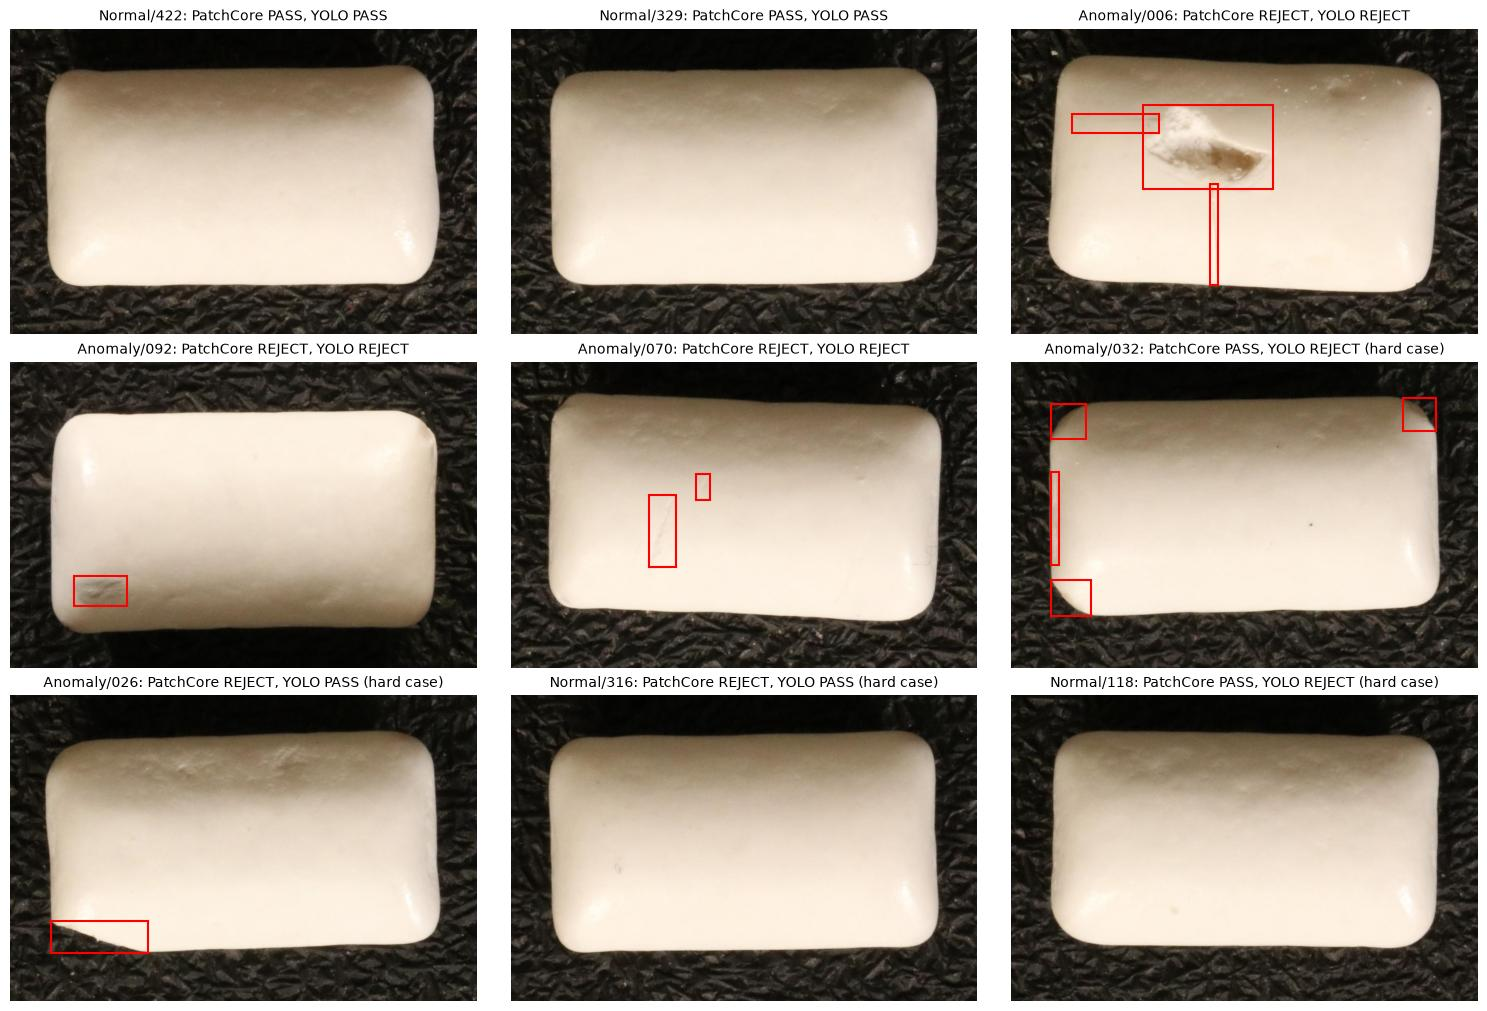

In [14]:
crops = pd.read_csv(CROP_TABLE_FILE)
crops["name"] = crops["image"].map(short_name)
crop_of = dict(zip(crops["name"], crops["crop_image"]))
real_boxes = pd.read_csv(BOX_FILE)
real_boxes["name"] = real_boxes["image"].map(short_name)
boxes_of = {name: rows[["left", "top", "right", "bottom", "defect type"]].values.tolist()
            for name, rows in real_boxes.groupby("name")}

fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
for ax, (_, row) in zip(axes.ravel(), gallery.iterrows()):
    ax.imshow(Image.open(os.path.join(CROP_DIR, *crop_of[row["name"]].split("/"))))
    draw_boxes(ax, boxes_of.get(row["name"], []))
    ax.set_title(f"{row['name']}: PatchCore {row['PatchCore']}, YOLO {row[f'YOLO k = {K}']}"
                 + (" (hard case)" if row["hard case"] else ""), fontsize=10)
    ax.axis("off")
plt.show()

### Save the Gallery

> Every crop is saved as a JPEG of quality 90 (about 10 times smaller than the PNG), only to be shown. The scores, heatmaps and boxes of the app come from the saved results of notebooks 4.1 and 4.3, which were made from the original crops. `gallery.csv` keeps the name, the file, the right answer and the real defect boxes of each photo.

In [15]:
os.makedirs(GALLERY_DIR, exist_ok=True)
rows = []
for _, row in gallery.iterrows():
    file_name = row["name"].replace("/", "_") + ".jpg"
    Image.open(os.path.join(CROP_DIR, *crop_of[row["name"]].split("/"))).convert("RGB").save(
        os.path.join(GALLERY_DIR, file_name), quality=GALLERY_QUALITY)
    rows.append({"name": row["name"], "file": file_name, "crop_image": crop_of[row["name"]], "is_defect": row["is_defect"],
                 "defect_types": row["defect_types"], "hard_case": row["hard case"],
                 "real_boxes": json.dumps(boxes_of.get(row["name"], []))})
gallery_table = pd.DataFrame(rows)
gallery_table.to_csv(os.path.join(APP_DATA_DIR, "gallery.csv"), index=False)
size_mb = sum(os.path.getsize(os.path.join(GALLERY_DIR, f)) for f in gallery_table["file"]) / 1024**2
print(f"Saved {len(gallery_table)} gallery photos ({size_mb:.1f} MB) and app/data/gallery.csv")

Saved 9 gallery photos (0.6 MB) and app/data/gallery.csv


### Camera Photo for the How It Works Page

> The page "How it works" of the app shows how a whole camera photo is cut. The crops of the gallery are already cut, so we also keep the whole photo of the first defect photo of the gallery, Anomaly/006.

In [16]:
camera_name = gallery.loc[gallery["is_defect"], "name"].iloc[0]
camera_file = camera_name.replace("/", "_") + "_camera.jpg"
raw_photo(camera_name).save(os.path.join(GALLERY_DIR, camera_file), quality=GALLERY_QUALITY)
print(f"Saved the camera photo of {camera_name} as app/data/gallery/{camera_file} "
      f"({os.path.getsize(os.path.join(GALLERY_DIR, camera_file)) / 1024**2:.1f} MB)")

Saved the camera photo of Anomaly/006 as app/data/gallery/Anomaly_006_camera.jpg (0.2 MB)


## 2. New Photos

### Check the Source Photos

> No new photo may come from a photo that a split 1 model learned from:
>
> - each good photo must be a left-out photo whose first photo (notebook 1.2) is not a train photo of split 1,
> - each base photo and each defect photo must be a test photo of split 1.

In [17]:
same_gum = pd.read_csv(os.path.join(SPLITS_DIR, "same_gum_photos.csv"))
same_gum = same_gum[same_gum["same_gum_as"].notna()].copy()
same_gum["name"] = same_gum["image"].map(short_name)
same_gum["first photo"] = same_gum["same_gum_as"].map(short_name)
same_gum["part of the first photo"] = same_gum["first photo"].map(part_of)
same_gum["part"] = same_gum["name"].map(part_of)
same_gum["usable"] = same_gum["part of the first photo"] != "train"
print("Left-out photos and their first photo in split 1:")
print(same_gum[["name", "part", "first photo", "part of the first photo", "usable"]].to_string(index=False))
print("\nAll good photos usable:", set(NEW_GOOD) <= set(same_gum.loc[same_gum["usable"], "name"]))
print("All base and defect photos are test photos of split 1:",
      all(part_of[name] == "test" for pair in NEW_DEFECTS for name in pair))

Left-out photos and their first photo in split 1:
      name     part first photo part of the first photo  usable
Normal/113 excluded  Normal/112                     val    True
Normal/216 excluded  Normal/215                    test    True
Normal/265 excluded  Normal/264                     val    True
Normal/300 excluded  Normal/299                   train   False
Normal/351 excluded  Normal/350                    test    True
Normal/501 excluded  Normal/500                   train   False

All good photos usable: True
All base and defect photos are test photos of split 1: True


> **What we see:**
>
> - 4 of the 6 left-out photos can be used: Normal/113, 216, 265 and 351. Their first photo is a validation or test photo of split 1.
> - Normal/300 and 501 cannot be used: their first photo is a train photo of split 1, so PatchCore and YOLO of split 1 learned this gum.
> - Every base photo and every defect photo is a test photo of split 1.

### Make the New Photos

> For every new photo:
>
> - **good:** open the left-out photo and mirror it.
> - **defect:** open the good test photo and mirror it, find both gums, guess where the defect goes, improve the guess with the outline, and copy the defect.
>
> Then the photo is cut with the crop rule, to check what the app will see. Nothing is saved yet.

In [18]:
plans = {f"good {i}": (name, "") for i, name in enumerate(NEW_GOOD, start=1)}
plans.update({f"defect {i}": pair for i, pair in enumerate(NEW_DEFECTS, start=1)})

new_photos = []
for number, plan in enumerate(ORDER, start=1):
    base_name, source_name = plans[plan]
    photo = raw_photo(base_name).transpose(Image.FLIP_LEFT_RIGHT)
    boxes, guess, shift = [], (0, 0), (0, 0)
    if source_name:
        source = raw_photo(source_name)
        codes = raw_mask(source_name)
        source_gum = find_gum_box(source.convert("L"), scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)
        target_gum = find_gum_box(photo.convert("L"), scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)
        guess = defect_shift(source_gum, target_gum, codes)
        shift = match_outline(source, photo, codes, guess=guess, search=SEARCH, margin=OUTLINE_MARGIN,
                              brightness=GUM_BRIGHTNESS)
        pixels, moved = copy_defect(np.asarray(photo), np.asarray(source), codes, shift=shift, grow=GROW, cover=COVER, ring=RING,
                                    soft_edge=SOFT_EDGE, bright=BRIGHT_GUM)
        photo = Image.fromarray(pixels)
        boxes = defect_boxes(moved, min_pixels=MIN_PIECE, mask_code=MASK_CODE)
    crop, window = cut_gum(photo, window_size=WINDOW_SIZE, scale=FIND_SCALE, brightness=GUM_BRIGHTNESS)
    types = sorted({box[4] for box in boxes})
    made_from = f"{base_name} mirrored" + (f", defect copied from {source_name}" if source_name else ", left out in notebook 1.2")
    new_photos.append({"file": f"photo_{number:02d}.jpg", "right_answer": "REJECT" if boxes else "PASS",
                       "defect_types": ",".join(types), "made_from": made_from, "guess": guess, "shift": shift, "window": window,
                       "real_boxes": boxes, "photo": photo, "crop": crop})

pd.DataFrame(new_photos)[["file", "right_answer", "defect_types", "made_from", "guess", "shift", "window"]]

,file,right_answer,defect_types,made_from,guess,shift,window
0,photo_01.jpg,PASS,,"Normal/113 mirrored, left out in notebook 1.2","(0, 0)","(0, 0)","(206, 362, 1134, 970)"
1,photo_02.jpg,REJECT,chunk of gum missing,"Normal/031 mirrored, defect copied from Anomal...","(60, -36)","(60, -36)","(250, 324, 1178, 932)"
2,photo_03.jpg,PASS,,"Normal/216 mirrored, left out in notebook 1.2","(0, 0)","(0, 0)","(204, 330, 1132, 938)"
3,photo_04.jpg,REJECT,similar colour spot,"Normal/375 mirrored, defect copied from Anomal...","(31, 18)","(31, 18)","(192, 374, 1120, 982)"
4,photo_05.jpg,REJECT,corner missing,"Normal/332 mirrored, defect copied from Anomal...","(32, -8)","(36, -26)","(248, 364, 1176, 972)"
5,photo_06.jpg,PASS,,"Normal/265 mirrored, left out in notebook 1.2","(0, 0)","(0, 0)","(166, 362, 1094, 970)"
6,photo_07.jpg,REJECT,scratches,"Normal/366 mirrored, defect copied from Anomal...","(-23, 5)","(-35, 14)","(234, 346, 1162, 954)"
7,photo_08.jpg,REJECT,"corner missing,scratches","Normal/471 mirrored, defect copied from Anomal...","(82, -14)","(79, -11)","(262, 360, 1190, 968)"
8,photo_09.jpg,PASS,,"Normal/351 mirrored, left out in notebook 1.2","(0, 0)","(0, 0)","(226, 310, 1154, 918)"


### Preview

> The new photos as the app will see them: cut out with the crop rule, with the real defect boxes in red.

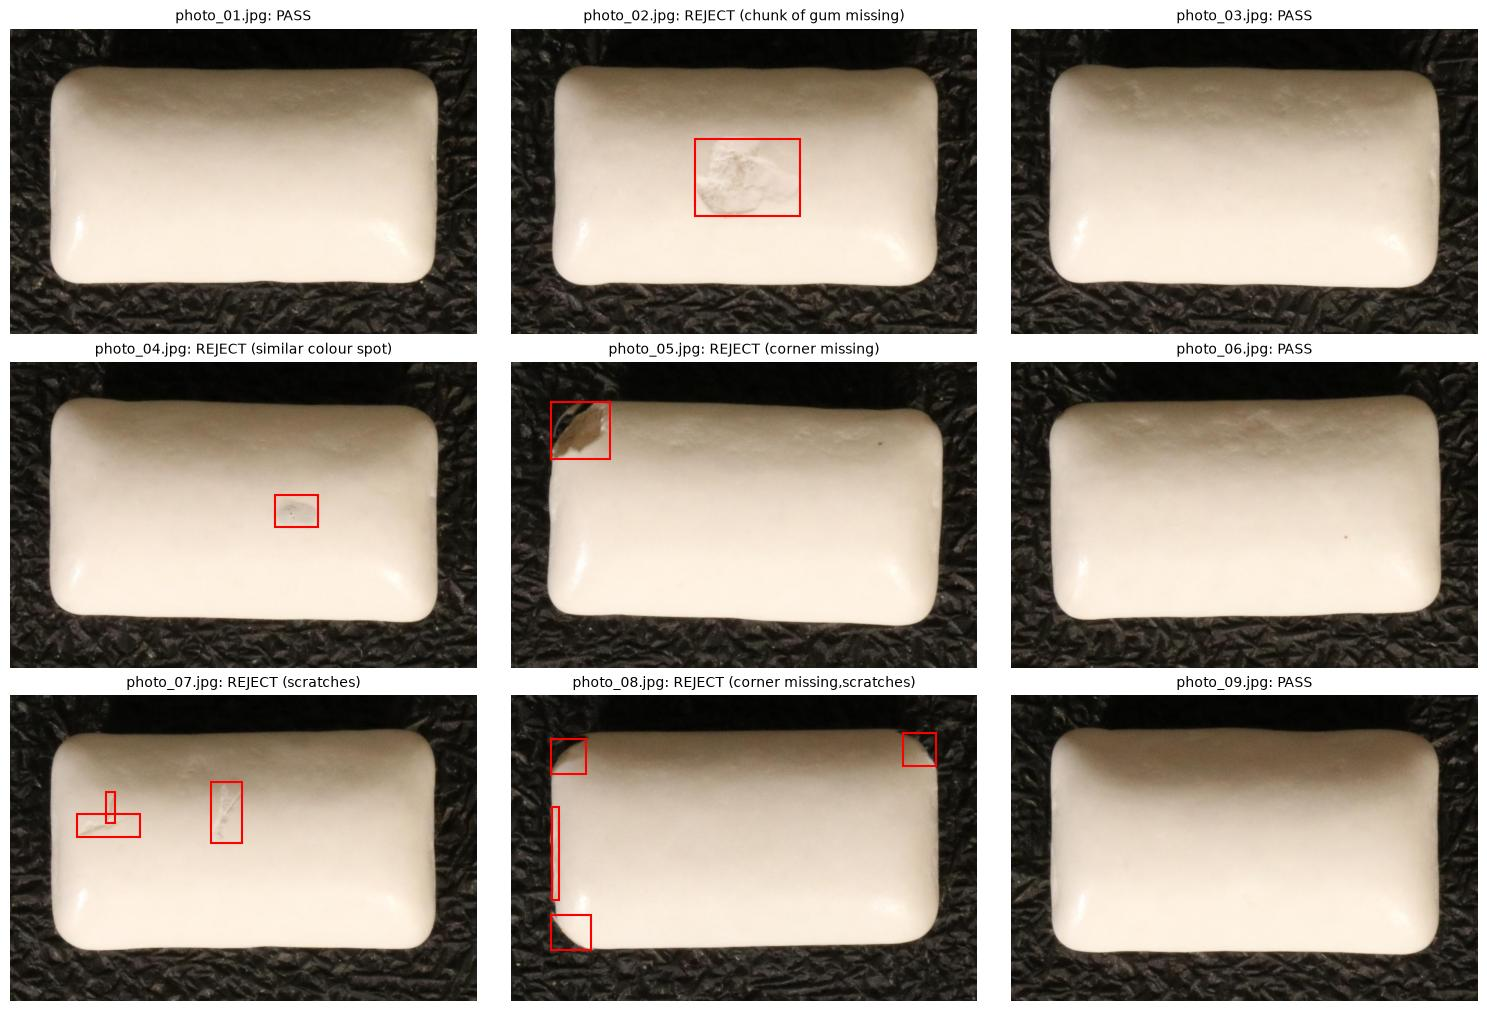

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
for ax, new in zip(axes.ravel(), new_photos):
    ax.imshow(new["crop"])
    draw_boxes(ax, new["real_boxes"], offset=new["window"][:2])
    ax.set_title(f"{new['file']}: {new['right_answer']}" + (f" ({new['defect_types']})" if new["defect_types"] else ""), fontsize=10)
    ax.axis("off")
plt.show()

### Close-up of the Copied Defects

> Each copied defect next to the original defect, both with 60 pixels around it, to check that the copy looks like the real one.

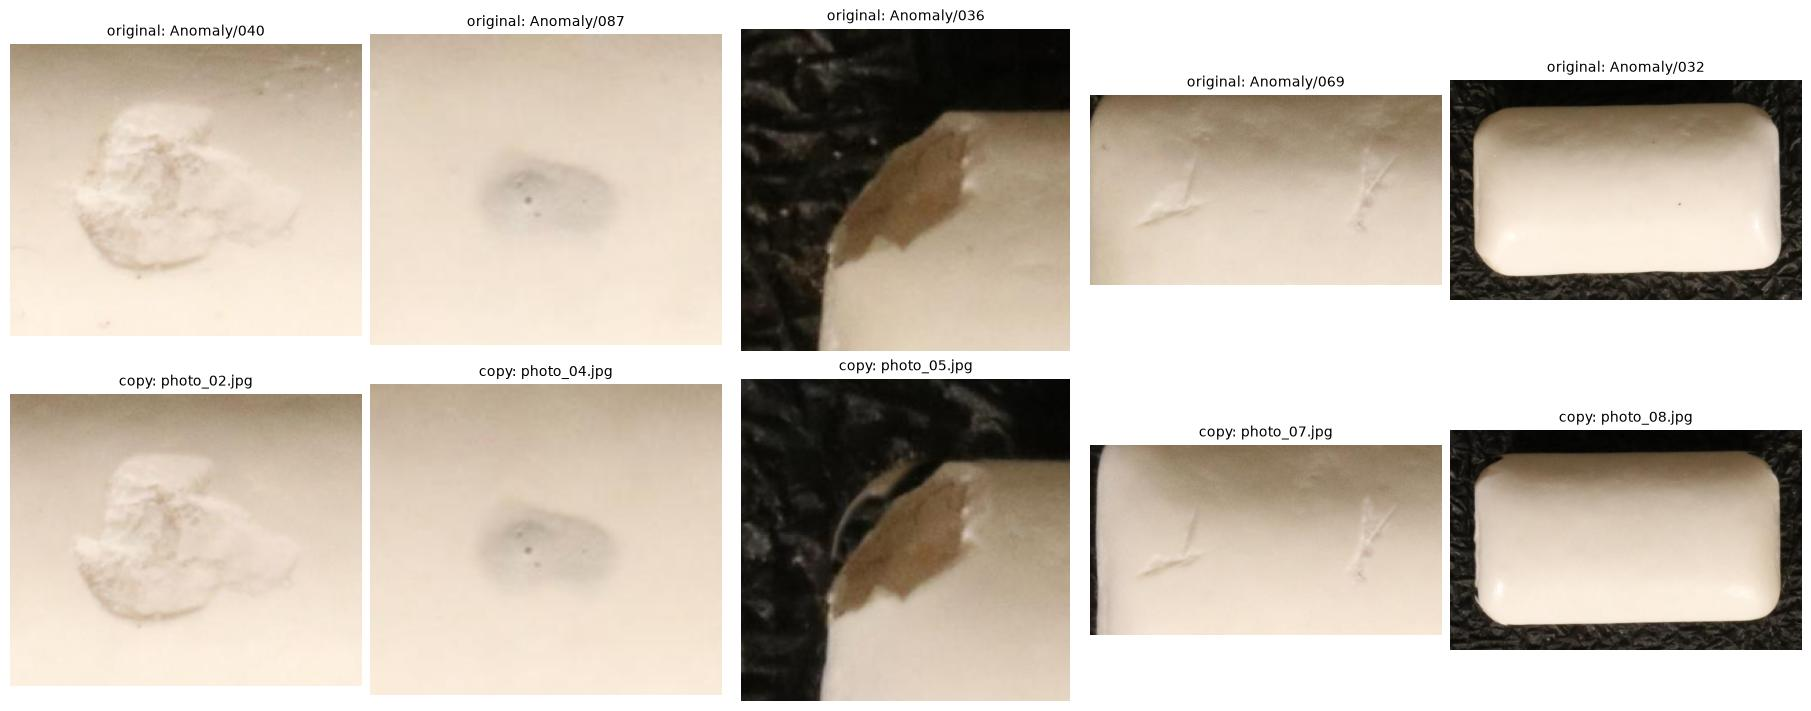

In [20]:
defect_photos = [new for new in new_photos if new["real_boxes"]]
fig, axes = plt.subplots(2, len(defect_photos), figsize=(18, 7), layout="constrained")
for col, new in enumerate(defect_photos):
    source_name = new["made_from"].split("from ")[-1]
    left = min(box[0] for box in new["real_boxes"]) - 60
    top = min(box[1] for box in new["real_boxes"]) - 60
    right = max(box[2] for box in new["real_boxes"]) + 60
    bottom = max(box[3] for box in new["real_boxes"]) + 60
    dx, dy = new["shift"]
    axes[0, col].imshow(raw_photo(source_name).crop((left - dx, top - dy, right - dx, bottom - dy)))
    axes[0, col].set_title(f"original: {source_name}", fontsize=10)
    axes[1, col].imshow(new["photo"].crop((left, top, right, bottom)))
    axes[1, col].set_title(f"copy: {new['file']}", fontsize=10)
for ax in axes.ravel():
    ax.axis("off")
plt.show()

> **What we see:**
>
> - The chunk, the colour spot and the scratches look the same as on their own gum. The soft edges and the brightness match leave no visible border.
> - The missing corner (photo_05) sits on the corner of the new gum. A thin light line is left where the old and the new gum outline are not exactly the same.
> - photo_08 gets the tiny broken corners of Anomaly/032. They are hard to see, as on the original photo.

### Save the New Photos

> The whole photos are saved as JPEG, like a camera would save them. `answers.csv` keeps the right answer, the defect types, how each photo was made and the real defect boxes in pixels of the whole photo.

In [21]:
os.makedirs(TEST_PHOTO_DIR, exist_ok=True)
for new in new_photos:
    new["photo"].save(os.path.join(TEST_PHOTO_DIR, new["file"]), quality=JPEG_QUALITY)
answers = pd.DataFrame([{key: (json.dumps(value) if key == "real_boxes" else value) for key, value in new.items()
                         if key in ["file", "right_answer", "defect_types", "made_from", "real_boxes"]} for new in new_photos])
answers.to_csv(os.path.join(TEST_PHOTO_DIR, "answers.csv"), index=False)
size_mb = sum(os.path.getsize(os.path.join(TEST_PHOTO_DIR, new["file"])) for new in new_photos) / 1024**2
print(f"Saved {len(new_photos)} new photos ({size_mb:.1f} MB) and test_photos/answers.csv")
print("Right answers:", answers["right_answer"].value_counts().to_dict())

Saved 9 new photos (2.8 MB) and test_photos/answers.csv
Right answers: {'REJECT': 5, 'PASS': 4}


## 3. Fingerprints

### Fingerprints of All Crops

> The fingerprint of every crop of the dataset (603 photos). To choose the limit for "the same photo", we compare:
>
> - **the same photo saved again as JPEG** (quality 60 and 90), like a photo that was downloaded and uploaded again: the difference should be very small,
> - **different photos:** the smallest difference between two different crops of the dataset, which are the same-gum pairs of notebook 1.2.

In [22]:
prints = np.stack([fingerprint(Image.open(os.path.join(CROP_DIR, *rel.split("/"))), size=FINGERPRINT_SIZE)
                   for rel in crops["crop_image"]])
closest = np.full(len(prints), np.inf)
for i in range(len(prints)):
    distances = np.abs(prints - prints[i]).mean(axis=(1, 2))
    distances[i] = np.inf
    closest[i] = distances.min()

saved_again = []
for rel in crops["crop_image"].iloc[::10]:
    crop = Image.open(os.path.join(CROP_DIR, *rel.split("/"))).convert("RGB")
    for quality in [60, 90]:
        buffer = io.BytesIO()
        crop.save(buffer, format="JPEG", quality=quality)
        saved_again.append(fingerprint_distance(fingerprint(Image.open(buffer), size=FINGERPRINT_SIZE),
                                                fingerprint(crop, size=FINGERPRINT_SIZE)))

print(f"Same photo saved again as JPEG ({len(saved_again)} tries): largest difference {max(saved_again):.2f}")
print(f"Two different photos: smallest difference {closest.min():.2f} "
      f"({(closest < 4).sum()} photos have another photo closer than 4)")

Same photo saved again as JPEG (122 tries): largest difference 0.27
Two different photos: smallest difference 1.01 (12 photos have another photo closer than 4)


> **What we see:**
>
> - The same photo, saved again as JPEG, changes its fingerprint by at most 0.27.
> - Two different photos differ by at least 1.01. Only 12 photos have another photo closer than 4: the 6 gums photographed twice (notebook 1.2).

### Limit and Check

> The limit lies in the middle between the largest difference of the same photo and the smallest difference of two different photos. The new photos must be far from every crop of the dataset: they are new pictures, not copies.

In [23]:
MATCH_LIMIT = round((max(saved_again) + closest.min()) / 2, 2)
print(f"Limit for 'the same photo': {MATCH_LIMIT}")
for new in new_photos:
    distances = np.abs(prints - fingerprint(new["crop"], size=FINGERPRINT_SIZE)).mean(axis=(1, 2))
    nearest = crops["name"].iloc[distances.argmin()]
    print(f"{new['file']}: closest dataset photo {nearest} at {distances.min():.2f} -> "
          f"{'SAME PHOTO' if distances.min() <= MATCH_LIMIT else 'new photo'}")

Limit for 'the same photo': 0.64
photo_01.jpg: closest dataset photo Normal/113 at 6.44 -> new photo
photo_02.jpg: closest dataset photo Normal/318 at 6.95 -> new photo
photo_03.jpg: closest dataset photo Normal/145 at 7.43 -> new photo
photo_04.jpg: closest dataset photo Normal/145 at 7.43 -> new photo
photo_05.jpg: closest dataset photo Normal/277 at 9.62 -> new photo
photo_06.jpg: closest dataset photo Normal/343 at 6.40 -> new photo
photo_07.jpg: closest dataset photo Normal/340 at 6.59 -> new photo
photo_08.jpg: closest dataset photo Normal/464 at 6.47 -> new photo
photo_09.jpg: closest dataset photo Normal/351 at 7.01 -> new photo


> **What we see:**
>
> - The limit is 0.64: an uploaded photo that differs by 0.64 or less from a crop of the dataset is that photo.
> - Every new photo differs by at least 6.40 from every crop of the dataset, so the app treats them as new photos. A mirrored photo is a different picture for the fingerprint, as it is for the models.

### Save the Fingerprints

> One file for the app: the fingerprints (as small numbers, `float16`), the name and the part in split 1 of every crop, and the limit.

In [24]:
os.makedirs(APP_DATA_DIR, exist_ok=True)
np.savez_compressed(os.path.join(APP_DATA_DIR, "fingerprints.npz"), prints=prints.astype(np.float16),
                    names=crops["name"].to_numpy(dtype=str), parts=crops["name"].map(part_of).to_numpy(dtype=str),
                    limit=np.array(MATCH_LIMIT))
size_mb = os.path.getsize(os.path.join(APP_DATA_DIR, "fingerprints.npz")) / 1024**2
print(f"Saved app/data/fingerprints.npz: {len(prints)} fingerprints, {size_mb:.1f} MB")

Saved app/data/fingerprints.npz: 603 fingerprints, 1.1 MB


## Conclusion

> **What this notebook did**
>
> - Saved the 9 gallery photos of the app (test photos of split 1), their real defect boxes and one whole camera photo in `app/data/`.
> - Made 9 new camera photos in `test_photos/`, with their right answers in `answers.csv`: mirrored photos that no split 1 model learned from, 5 of them with a real defect copied from a test photo of split 1.
> - Saved a fingerprint of every crop, so the app can say when an uploaded photo is a photo of the dataset, and which part of split 1 it belongs to.
>
> **Data leakage:** nothing here changes a model, a limit or a result. The new photos only use left-out photos and test photos of split 1, which no split 1 model learned from.
>
> **Next:** the app (`app/streamlit_app.py`, see README > Demo).